# Midterm

**Тема:** сервис, который по входным данным блюда (название, категория, ингредиенты) генерирует короткое описание блюда на русском языке.

## 1. Установка и конфигурация

In [ ]:
%pip install -q sacrebleu rouge-score bert-score sentencepiece peft scikit-learn

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import gc, json, os, random, re, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from huggingface_hub import hf_hub_download
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM,
                          DataCollatorForSeq2Seq, Seq2SeqTrainer, Seq2SeqTrainingArguments, set_seed)
import sacrebleu
from rouge_score import rouge_scorer
from bert_score import score as bert_score

CONFIG = {
    "seed": 42,
    "dataset_repo": "d0rj/povarenok_recipes_detail",
    "train_size": 10_000,
    "val_size": 1_000,
    "test_size": 300,
    "min_words": 6, "max_words": 35,
    "t5_model": "ai-forever/ruT5-base",
    "llm_model": "Qwen/Qwen2.5-0.5B-Instruct",
    "bertscore_model": "cointegrated/rubert-tiny2",
    "max_source_len": 128, "max_target_len": 80,
    "epochs": 2, "batch_size": 8,
    "learning_rate": 5e-4, "optimizer": "adafactor",
    "weight_decay": 0.0, "warmup_ratio": 0.05,
    "num_beams": 4, "no_repeat_ngram_size": 3, "max_new_tokens": 80,
    "max_chars": 300,
}

set_seed(CONFIG["seed"]); random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"])
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
OUT_DIR = Path("results"); OUT_DIR.mkdir(exist_ok=True)
print("Device:", DEVICE, "| torch", torch.__version__)
print(json.dumps(CONFIG, indent=2, ensure_ascii=False))

Device: cuda | torch 2.11.0+cu130
{
  "seed": 42,
  "dataset_repo": "d0rj/povarenok_recipes_detail",
  "train_size": 10000,
  "val_size": 1000,
  "test_size": 300,
  "min_words": 6,
  "max_words": 35,
  "t5_model": "ai-forever/ruT5-base",
  "llm_model": "Qwen/Qwen2.5-0.5B-Instruct",
  "bertscore_model": "cointegrated/rubert-tiny2",
  "max_source_len": 128,
  "max_target_len": 80,
  "epochs": 2,
  "batch_size": 8,
  "learning_rate": 0.0005,
  "optimizer": "adafactor",
  "weight_decay": 0.0,
  "warmup_ratio": 0.05,
  "num_beams": 4,
  "no_repeat_ngram_size": 3,
  "max_new_tokens": 80,
  "max_chars": 300
}


In [ ]:
import importlib.metadata as md, platform, sys
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
os.environ["PYTHONHASHSEED"] = str(CONFIG["seed"])

PKGS = ["torch", "transformers", "datasets", "peft", "accelerate", "scikit-learn", "sacrebleu",
        "rouge-score", "bert-score", "sentencepiece", "huggingface_hub", "pandas", "numpy"]
ENV = {"python": sys.version.split()[0], "platform": platform.platform(), "device": DEVICE}
if DEVICE == "cuda":
    ENV["gpu"] = torch.cuda.get_device_name(0)
for p in PKGS:
    try:
        ENV[p] = md.version(p)
    except md.PackageNotFoundError:
        ENV[p] = "not installed"
(OUT_DIR / "environment.json").write_text(json.dumps(ENV, indent=2, ensure_ascii=False))
pd.Series(ENV).to_frame("version")

,version
python,3.13.16
platform,Linux-6.6.122+-x86_64-with-glibc2.39
device,cuda
gpu,Tesla T4
torch,2.11.0+cu130
transformers,5.20.2
datasets,4.8.5
peft,0.21.2
accelerate,1.15.0
scikit-learn,1.6.1


## 2. Данные

**Источник:** [d0rj/povarenok_recipes_detail](https://huggingface.co/datasets/d0rj/povarenok_recipes_detail) (Hugging Face, лицензия Apache-2.0) — 154 158 рецептов с сайта povarenok.ru, на русском языке. Для каждой записи есть ровно то, что будет у партнёра маркетплейса:

**title** - название блюда

**kroshki** - категория

**ingredients** - ингредиенты

**description** - короткое описание блюда

In [ ]:
PARQUET_FILES = ["data/train-00000-of-00002-d1fbf0221320b7a4.parquet",
                 "data/train-00001-of-00002-8ce75ff1e8c43597.parquet"]
COLUMNS = ["title", "description", "kroshki", "ingredients"]

frames = []
for fname in PARQUET_FILES:
    local_path = hf_hub_download(CONFIG["dataset_repo"], fname, repo_type="dataset")
    frames.append(pd.read_parquet(local_path, columns=COLUMNS))
raw = pd.concat(frames, ignore_index=True)

print("Shape:", raw.shape)
raw.head(3)

data/train-00000-of-00002-d1fbf0221320b7(…): reconstructing file:   0%|          |  0.00B / 91.7MB            

data/train-00000-of-00002-d1fbf0221320b7(…): downloading bytes:           |  0.00B            

data/train-00001-of-00002-8ce75ff1e8c435(…): reconstructing file:   0%|          |  0.00B /  108MB            

data/train-00001-of-00002-8ce75ff1e8c435(…): downloading bytes:           |  0.00B            

Shape: (154158, 4)


,title,description,kroshki,ingredients
0,"Бутерброды ""Кораблики с икрой""",Как можно украсить обычные бутерброды с красно...,"[Закуски, Бутерброды, Открытый бутерброд]","[{'count': None, 'name': 'Батон'}, {'count': '..."
1,Баклажаны с грибами под сметаной,Обжаренные баклажаны с жареными грибами в смет...,"[Горячие блюда, Запеканки, Запеканка с овощами]","[{'count': '500 г', 'name': 'Баклажан'}, {'cou..."
2,Мясо в сухарях,"Отбитые кусочки мяса, обжаренные в панировочн...","[Горячие блюда, Блюда из мяса, Горячие блюда ...","[{'count': '800 г', 'name': 'Свинина'}, {'coun..."


## 3. Очистка: оставляем только «меню-подобные» описания

Из-за того, что описания на сайте пишут сами пользователи, многие из них содержат лишнюю информацию (личные истории и т.д.).

Поэтому вводим фильтры, каждый отдельно обоснован и посчитан (до/после):

1. пустое описание или нет ингредиентов → нечего учить;
2. первое лицо и служебные слова (я, мой, муж, конкурс, поварята, рецепт, сайт…) → стиль, недопустимый в карточке товара;
3. ссылки, смайлики `:-)`, `!!`, переносы строк → форумный стиль, не подходит для задачи;
4. длина вне 6–35 слов → слишком коротко (нет содержания) или слишком длинно для карточки;
5. точные дубликаты (название + описание).

In [ ]:
FIRST_PERSON = re.compile(
    r"\b(я|мне|меня|мой|моя|моё|мое|мои|моих|моим|мы|нас|нам|наш|наша|наши|наше|"
    r"муж\w*|доч\w*|сын\w*|свекр\w*|мам\w*|бабушк\w*|подруг\w*|внук\w*|"
    r"поварят\w*|поварён\w*|поварен\w*|конкурс\w*|рецепт\w*|сайт\w*|"
    r"делюсь|предлагаю|приготовила|пекла|нашла|готовлю|спасибо|решила|решил|хочу|думаю)\b", re.IGNORECASE)
FORUM_STYLE = re.compile(r"http|www|\)\)|!!|:-|;-|\n")

def ingredient_names(items):
    if items is None:
        return []
    return [str(it["name"]).strip() for it in items if it.get("name")]

df = raw.copy()
df["description"] = df["description"].fillna("").astype(str).str.strip()
df["ingr_list"] = df["ingredients"].apply(ingredient_names)
df["n_words"] = df["description"].str.split().str.len()

log = [("raw", len(df))]
df = df[(df["description"] != "") & (df["ingr_list"].str.len() > 0)];          log.append(("1. non-empty desc & ingredients", len(df)))
df = df[~df["description"].apply(lambda s: bool(FIRST_PERSON.search(s)))];      log.append(("2. no first person / site meta-text", len(df)))
df = df[~df["description"].apply(lambda s: bool(FORUM_STYLE.search(s)))];       log.append(("3. no links / emoticons / line breaks", len(df)))
df = df[df["n_words"].between(CONFIG["min_words"], CONFIG["max_words"])];       log.append(("4. 6-35 words", len(df)))
df = df.drop_duplicates(subset=["title", "description"]);                        log.append(("5. drop exact duplicates", len(df)))

clean_log = pd.DataFrame(log, columns=["step", "rows_left"])
clean_log["removed"] = (-clean_log["rows_left"].diff()).fillna(0).astype(int)
clean_log["kept_%_of_raw"] = (100 * clean_log["rows_left"] / len(raw)).round(1)
clean_log

,step,rows_left,removed,kept_%_of_raw
0,raw,154158,0,100.0
1,1. non-empty desc & ingredients,154150,8,100.0
2,2. no first person / site meta-text,68355,85795,44.3
3,3. no links / emoticons / line breaks,57791,10564,37.5
4,4. 6-35 words,43885,13906,28.5
5,5. drop exact duplicates,43881,4,28.5


In [ ]:
removed_example = raw[raw["description"].fillna("").apply(lambda s: bool(FIRST_PERSON.search(s)))].sample(3, random_state=1)
print("REMOVED (first person / meta):")
for t, d in zip(removed_example["title"], removed_example["description"]):
    print(f"  - {t}: {d[:160]}")
print("\nKEPT:")
for t, d in zip(df.sample(5, random_state=1)["title"], df.sample(5, random_state=1)["description"]):
    print(f"  - {t}: {d}")

del raw, frames; gc.collect()

REMOVED (first person / meta):
  - Баклажаны с грецкими орехами: Рецепт от "грузинской" свекрови моей подруги. Грузинская кухня полна зелени, овощей и приправ! Вкусная и полезная! Этот рецепт понравится вегетарианцам
  - Рагу с бараниной: Готовил мой муж - большой любитель баранины. Не судите строго, было очень вкусно!!!
  - Коктейль "Рубиновые краски": Насыщенный смородиновый вкус с нотками апельсинового вкуса. 

На конкурс "Утомленные солнцем"

KEPT:
  - Курица карри в молоке: Нежная куриная грудка, тушеная в молоке с приправой карри, готовится быстро и очень вкусно.
  - Хот-дог по-селянски: Простой хлебушек с начинкой всегда найдeт своего почитателя. Иногда хочется без колбас, а, например, с грибами...
  - Пирог "Кучерявчик": Вкусный пирог из песочного теста, очень нежный, а главное, простой в приготовлении!
  - Китайский салат с курицей: Очень легкий в приготовлении салатик из простых, доступных ингредиентов (несмотря на длинный список). Можно заранее дома приготовить, а можно и на

20

## 4. Формирование входа (X) и цели (y)

- **X (source)** — вводный текст из трёх полей: блюдо, категория, ингредиенты.
- **y (target)** — описание блюда.

In [ ]:
def make_source(title, kroshki, ingr_list):
    category = " > ".join(list(kroshki)[:2]) if kroshki is not None and len(kroshki) else "—"
    return f"Блюдо: {title}\nКатегория: {category}\nИнгредиенты: {', '.join(ingr_list)}"

df["category_top"] = df["kroshki"].apply(lambda k: k[0] if k is not None and len(k) else "—")
df["source"] = [make_source(t, k, i) for t, k, i in zip(df["title"], df["kroshki"], df["ingr_list"])]
df["target"] = df["description"]

print(df["source"].iloc[0]); print("→", df["target"].iloc[0])

Блюдо: Бутерброды "Кораблики с икрой"
Категория: Закуски > Бутерброды
Ингредиенты: Батон, Икра красная, Маслины, Лимон, Зелень, Масло сливочное
→ Как можно украсить обычные бутерброды с красной икрой


## 5. Разбиение train / validation / test без утечки

В датасете есть рецепты с одинаковым названием, и если такие попадут и в train, и в test, модель будет проверяться на уже знакомых примерах (data leakage)

Поэтому делим по группам нормализованного названия: все рецепты с одним названием попадают только в одну часть (80 / 10 / 10 % групп). Затем берём подвыборки нужного размера (`train_size`, `val_size`, `test_size`) — ограничение по времени обучения на бесплатном GPU.

In [ ]:
def normalize_title(t):
    return " ".join(re.sub(r"[^\w\s]", " ", str(t).lower()).split())

df["title_group"] = df["title"].apply(normalize_title)
groups = np.array(sorted(df["title_group"].unique()))
rng = np.random.default_rng(CONFIG["seed"])
rng.shuffle(groups)
n = len(groups)
g_train, g_val, g_test = set(groups[: int(.8 * n)]), set(groups[int(.8 * n): int(.9 * n)]), set(groups[int(.9 * n):])

train_full = df[df["title_group"].isin(g_train)]
val_full   = df[df["title_group"].isin(g_val)]
test_full  = df[df["title_group"].isin(g_test)]

train_df = train_full.sample(min(CONFIG["train_size"], len(train_full)), random_state=CONFIG["seed"]).reset_index(drop=True)
val_df   = val_full.sample(min(CONFIG["val_size"], len(val_full)), random_state=CONFIG["seed"]).reset_index(drop=True)
test_df  = test_full.sample(min(CONFIG["test_size"], len(test_full)), random_state=CONFIG["seed"]).reset_index(drop=True)

print("Available after split:", len(train_full), len(val_full), len(test_full))
del train_full, val_full, test_full, df; gc.collect()

print("Used:", len(train_df), len(val_df), len(test_df))
print("Title overlap train∩test:", len(set(train_df.title_group) & set(test_df.title_group)),
      "| train∩val:", len(set(train_df.title_group) & set(val_df.title_group)))


pd.concat({"train": train_df.category_top.value_counts(normalize=True),
           "test": test_df.category_top.value_counts(normalize=True)}, axis=1).head(8).round(3)

Available after split: 35125 4354 4402
Used: 10000 1000 300
Title overlap train∩test: 0 | train∩val: 0


,train,test
category_top,,
Горячие блюда,0.282,0.310
Выпечка,0.211,0.160
Десерты,0.140,0.127
Салаты,0.134,0.123
Закуски,0.111,0.117
Бульоны и супы,0.042,0.060
Заготовки,0.020,0.030
Напитки,0.019,0.010


## 6. Метрики

**chrF++**: проверяет совпадение символьных n-грамм с эталоном (0-100); нужен из-за того что в русском языке есть разные окончания.

**ROUGE-L**: самая длинная общая последовательность слов (0-100); проверяет сохраняет ли модель порядок фразы из эталона.

**BERTScore F1:** оценивает смысловую близость.




- `len_ok_%` — доля описаний ≤ 300 символов;
- `ingredient_mention_%` — доля описаний, где упомянут хотя бы один ингредиент из входа (опора на данные);
- `health_claim_%` — «полезный», «диетический», «низкокалорийный»… (запрещено требованиями);
- `first_person_%` — «я / мой / муж…» (стиль форума);
- `distinct_2` — доля уникальных биграмм во всех ответах.

In [ ]:
class SimpleTokenizer:

    def tokenize(self, text):
        return re.findall(r"\w+", text.lower())

ROUGE = rouge_scorer.RougeScorer(["rougeL"], tokenizer=SimpleTokenizer())
HEALTH_CLAIM = re.compile(r"\b(полезн\w*|диетич\w*|низкокалор\w*|здоров\w*|витамин\w*|похуд\w*|самый|самая|самое|лучш\w*|идеальн\w*)\b", re.I)

def stem_set(text, k=5):
    # грубая «лемматизация»: первые k букв слов длиной ≥4
    return {w[:k] for w in re.findall(r"\w+", text.lower()) if len(w) >= 4}

def distinct_2(texts):
    bigrams = [tuple(t[i:i + 2]) for t in (re.findall(r"\w+", x.lower()) for x in texts) for i in range(len(t) - 1)]
    return len(set(bigrams)) / max(len(bigrams), 1)

def evaluate(preds, data, name):
    refs = data["target"].tolist()
    chrf = sacrebleu.corpus_chrf(preds, [refs], word_order=2).score          # word_order=2 → chrF++
    rouge_l = 100 * np.mean([ROUGE.score(r, p)["rougeL"].fmeasure for r, p in zip(refs, preds)])
    _, _, f1 = bert_score(preds, refs, model_type=CONFIG["bertscore_model"], num_layers=3,
                          lang="ru", device=DEVICE, verbose=False)
    mention = [len(stem_set(" ".join(ing)) & stem_set(p)) > 0 for ing, p in zip(data["ingr_list"], preds)]
    return {
        "model": name,
        "chrF++": round(chrf, 2),
        "ROUGE-L": round(rouge_l, 2),
        "BERTScore_F1": round(100 * f1.mean().item(), 2),
        "len_ok_%": round(100 * np.mean([len(p) <= CONFIG["max_chars"] for p in preds]), 1),
        "ingredient_mention_%": round(100 * np.mean(mention), 1),
        "health_claim_%": round(100 * np.mean([bool(HEALTH_CLAIM.search(p)) for p in preds]), 1),
        "first_person_%": round(100 * np.mean([bool(FIRST_PERSON.search(p)) for p in preds]), 1),
        "distinct_2": round(distinct_2(preds), 3),
        "avg_chars": round(np.mean([len(p) for p in preds]), 0),
    }

def per_item_chrf(preds, refs):
    return [sacrebleu.sentence_chrf(p, [r], word_order=2).score for p, r in zip(preds, refs)]

results, predictions = [], {}

## 7. Модель 0 — шаблон без ML (нижняя граница)

Просто склеиваем поля: Название - категория. В составе: 3 первых ингредиента.»

In [ ]:
def template_description(row):
    ingr = ", ".join(i.lower() for i in row["ingr_list"][:3])
    return f"{row['title']} — {row['category_top'].lower()}. В составе: {ingr}."

predictions["Template"] = test_df.apply(template_description, axis=1).tolist()
results.append(evaluate(predictions["Template"], test_df, "Template (no ML)"))
print(predictions["Template"][:3]); pd.DataFrame(results)

config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


['Cуп с креветками — бульоны и супы. В составе: креветки, лук-порей, чеснок.', 'Крем-суп с копченостями — бульоны и супы. В составе: картофель, лук репчатый, бекон.', 'Картофельный пирог — выпечка. В составе: тесто слоеное бездрожжевое, картофель, сметана.']


,model,chrF++,ROUGE-L,BERTScore_F1,len_ok_%,ingredient_mention_%,health_claim_%,first_person_%,distinct_2,avg_chars
0,Template (no ML),17.17,11.51,48.47,100.0,100.0,1.3,0.3,0.539,85.0


## 8. Модель A — Qwen2.5-0.5B-Instruct, zero-shot (без обучения)


In [ ]:
SYSTEM_PROMPT = ("Ты — копирайтер фуд-маркетплейса. Напиши короткое аппетитное описание блюда для карточки меню "
                 "на русском языке: 1–2 предложения, не длиннее 200 символов. Опирайся только на перечисленные "
                 "ингредиенты, не придумывай новые. Без превосходных степеней и обещаний пользы для здоровья. "
                 "Выведи только текст описания.")

llm_tok = AutoTokenizer.from_pretrained(CONFIG["llm_model"], padding_side="left")
llm = AutoModelForCausalLM.from_pretrained(
    CONFIG["llm_model"], torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE).eval()

def llm_generate(sources, batch_size=16):
    outputs = []
    for i in range(0, len(sources), batch_size):
        prompts = [llm_tok.apply_chat_template(
            [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": s}],
            tokenize=False, add_generation_prompt=True) for s in sources[i:i + batch_size]]
        enc = llm_tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
        with torch.no_grad():
            gen = llm.generate(**enc, max_new_tokens=CONFIG["max_new_tokens"], do_sample=False,
                               repetition_penalty=1.1, pad_token_id=llm_tok.eos_token_id)
        outputs += llm_tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip().replace("\n", " ") for o in outputs]

t0 = time.time()
predictions["Qwen zero-shot"] = llm_generate(test_df["source"].tolist())
print(f"Generated {len(test_df)} in {time.time() - t0:.0f}s")
results.append(evaluate(predictions["Qwen zero-shot"], test_df, "Qwen2.5-0.5B zero-shot"))

# освобождаем память GPU перед обучением ruT5
del llm; gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None
pd.DataFrame(results)

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


... (4 outputs left out)

Generated 300 in 101s


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,model,chrF++,ROUGE-L,BERTScore_F1,len_ok_%,ingredient_mention_%,health_claim_%,first_person_%,distinct_2,avg_chars
0,Template (no ML),17.17,11.51,48.47,100.0,100.0,1.3,0.3,0.539,85.0
1,Qwen2.5-0.5B zero-shot,19.65,11.31,49.06,100.0,98.7,31.0,4.0,0.637,153.0


## 9. Модель B — ruT5-base, fine-tuning (основная baseline-модель)

Почему ruT5-base:
- архитектура encoder–decoder (seq2seq) - энкодер читает поля, декодер пишет описание (data-to-text);
- редобучена на русском корпусе, токенизатор на 32k токенов эффективен для кириллицы;
- 223M - полный fine-tuning (все веса), без LoRA.

Конфигурация обучения: 2 эпохи, batch 8, оптимизатор Adafactor (экономит память, стабилен), lr = 5e-4 с линейным затуханием, warmup 5 %, fp32 (у T5 в fp16 бывают переполнения → NaN).



In [ ]:
t5_tok = AutoTokenizer.from_pretrained(CONFIG["t5_model"])
t5 = AutoModelForSeq2SeqLM.from_pretrained(CONFIG["t5_model"])
print(f"Parameters: {sum(p.numel() for p in t5.parameters()) / 1e6:.0f}M")

def tokenize_batch(batch):
    enc = t5_tok(batch["source"], max_length=CONFIG["max_source_len"], truncation=True)
    enc["labels"] = t5_tok(text_target=batch["target"], max_length=CONFIG["max_target_len"], truncation=True)["input_ids"]
    return enc

train_ds = Dataset.from_pandas(train_df[["source", "target"]]).map(tokenize_batch, batched=True, remove_columns=["source", "target"])
val_ds   = Dataset.from_pandas(val_df[["source", "target"]]).map(tokenize_batch, batched=True, remove_columns=["source", "target"])

# Проверяем, что почти ничего не обрезается
src_len = [len(x) for x in train_ds["input_ids"]]; tgt_len = [len(x) for x in train_ds["labels"]]
print(f"source tokens: median {np.median(src_len):.0f}, truncated {np.mean(np.array(src_len) >= CONFIG['max_source_len']):.1%}")
print(f"target tokens: median {np.median(tgt_len):.0f}, truncated {np.mean(np.array(tgt_len) >= CONFIG['max_target_len']):.1%}")

config.json:   0%|          | 0.00/1.39k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/20.4k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B / 1.00MB            

spiece.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  892MB            

... (4 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  892MB            

model.safetensors: downloading bytes:           |  0.00B            

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

source tokens: median 63, truncated 0.2%
target tokens: median 28, truncated 0.0%


In [ ]:
import math
steps_total = math.ceil(len(train_ds) / CONFIG["batch_size"]) * CONFIG["epochs"]
warmup_steps = int(CONFIG["warmup_ratio"] * steps_total)
print("total steps:", steps_total, "| warmup steps:", warmup_steps)

args = Seq2SeqTrainingArguments(
    output_dir="rut5_checkpoints",
    num_train_epochs=CONFIG["epochs"],
    per_device_train_batch_size=CONFIG["batch_size"],
    per_device_eval_batch_size=CONFIG["batch_size"],
    learning_rate=CONFIG["learning_rate"],
    optim=CONFIG["optimizer"],
    weight_decay=CONFIG["weight_decay"],
    warmup_steps=warmup_steps,
    eval_strategy="epoch",
    save_strategy="no",
    logging_steps=25,
    report_to="none",
    seed=CONFIG["seed"],
    fp16=False,
)
trainer = Seq2SeqTrainer(model=t5, args=args, train_dataset=train_ds, eval_dataset=val_ds,
                         data_collator=DataCollatorForSeq2Seq(t5_tok, model=t5),
                         processing_class=t5_tok)
t0 = time.time()
train_output = trainer.train()
T5_TRAIN_MIN = (time.time() - t0) / 60
print(f"Training time: {T5_TRAIN_MIN:.1f} min | final train loss {train_output.training_loss:.3f}")

total steps: 2500 | warmup steps: 125


Epoch,Training Loss,Validation Loss
1,2.716823,2.718713
2,2.317899,2.531090


Training time: 16.1 min | final train loss 2.843


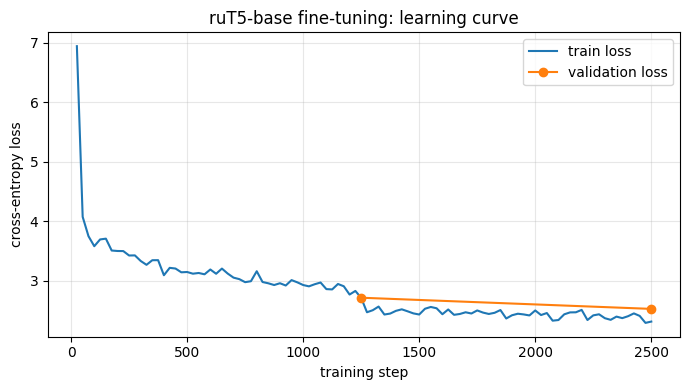

,epoch,eval_loss
50,1.0,2.718713
101,2.0,2.531090


In [ ]:
hist = pd.DataFrame(trainer.state.log_history)
tr = hist.dropna(subset=["loss"]) if "loss" in hist else hist.iloc[0:0]
ev = hist.dropna(subset=["eval_loss"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(tr["step"], tr["loss"], label="train loss")
ax.plot(ev["step"], ev["eval_loss"], "o-", label="validation loss")
ax.set_xlabel("training step"); ax.set_ylabel("cross-entropy loss"); ax.set_title("ruT5-base fine-tuning: learning curve")
ax.legend(); ax.grid(alpha=.3); plt.tight_layout(); plt.savefig(OUT_DIR / "learning_curve.png", dpi=150); plt.show()
ev[["epoch", "eval_loss"]]

In [ ]:
def t5_generate(sources, batch_size=32):
    t5.eval(); outputs = []
    for i in range(0, len(sources), batch_size):
        enc = t5_tok(sources[i:i + batch_size], max_length=CONFIG["max_source_len"], truncation=True,
                     padding=True, return_tensors="pt").to(t5.device)
        with torch.no_grad():
            gen = t5.generate(**enc, max_new_tokens=CONFIG["max_new_tokens"], num_beams=CONFIG["num_beams"],
                              no_repeat_ngram_size=CONFIG["no_repeat_ngram_size"], early_stopping=True)
        outputs += t5_tok.batch_decode(gen, skip_special_tokens=True)
    return [o.strip() for o in outputs]

t0 = time.time()
predictions["ruT5 fine-tuned"] = t5_generate(test_df["source"].tolist())
print(f"Generated {len(test_df)} in {time.time() - t0:.0f}s")
results.append(evaluate(predictions["ruT5 fine-tuned"], test_df, "ruT5-base fine-tuned"))
res3 = pd.DataFrame(results).set_index("model").loc[
    ["Template (no ML)", "Qwen2.5-0.5B zero-shot", "ruT5-base fine-tuned"]]
res3

Generated 300 in 17s


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,chrF++,ROUGE-L,BERTScore_F1,len_ok_%,ingredient_mention_%,health_claim_%,first_person_%,distinct_2,avg_chars
model,,,,,,,,,
Template (no ML),17.17,11.51,48.47,100.0,100.0,1.3,0.3,0.539,85.0
Qwen2.5-0.5B zero-shot,19.65,11.31,49.06,100.0,98.7,31.0,4.0,0.637,153.0
ruT5-base fine-tuned,14.55,17.57,51.51,100.0,68.7,17.0,0.0,0.539,49.0


## 9.0 Конфигурация дополнительных экспериментов и быстрые метрики

Все пространства поиска и параметры новых экспериментов собраны в одном месте (`EXTRA`), seed берётся из `CONFIG["seed"]`. Все модели ниже обучаются на **тех же** `train_df` / `val_df` и оцениваются на **том же** `test_df` теми же метриками, что и Template / Qwen zero-shot / ruT5 baseline.

Для подбора гиперпараметров используется быстрая оценка на **validation**: chrF++ при β = 1 и ROUGE-L. Критерий выбора — их среднее. β = 1 выбран потому, что при стандартном β = 2 метрика поощряет длинные ответы (см. диагностику длины в разделе 10), а подбор по ней привёл бы к выбору «болтливой» конфигурации. BERTScore считается только на финальном test (он медленнее).

In [ ]:
EXTRA = {
    "retr_analyzers": [("word", (1, 1)), ("word", (1, 2)), ("char_wb", (2, 4))],
    "retr_sublinear_tf": [False, True],
    "retr_fields": ["title", "full"],
    "retr_k": [1, 5],
    "tune_train_size": 3000, "tune_epochs": 1, "tune_val_gen_size": 200,
    "t5_search_space": {"learning_rate": [1e-4, 3e-4, 5e-4, 1e-3], "batch_size": [8, 16]},
    "decode_val_size": 300,
    "decode_search_space": {"num_beams": [1, 4], "no_repeat_ngram_size": [2, 3],
                            "length_penalty": [1.0, 2.0], "min_new_tokens": [0, 15]},
    "lora": {"r": 16, "alpha": 32, "dropout": 0.05,
             "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
             "learning_rate": 2e-4, "epochs": 2, "batch_size": 8, "max_len": 384,
             "optimizer": "adamw_torch", "weight_decay": 0.0, "warmup_ratio": 0.03, "max_new_tokens": 100},
}
PARAMS_M = {"Template (no ML)": 0.0, "kNN-TFIDF default": 0.0, "kNN-TFIDF tuned": 0.0, "Qwen2.5-0.5B zero-shot": 0.0}
PRED2RES = {"Template": "Template (no ML)", "Qwen zero-shot": "Qwen2.5-0.5B zero-shot",
            "ruT5 fine-tuned": "ruT5-base fine-tuned", "kNN default": "kNN-TFIDF default",
            "kNN tuned": "kNN-TFIDF tuned", "ruT5 + tuned decoding": "ruT5-base + tuned decoding",
            "ruT5 tuned": "ruT5-base tuned", "Qwen + LoRA": "Qwen2.5-0.5B + LoRA"}

def quick_score(preds, data):
    """Быстрые метрики для подбора гиперпараметров (chrF++ beta=1 и ROUGE-L), без BERTScore."""
    refs = data["target"].tolist()
    chrf1 = sacrebleu.CHRF(word_order=2, beta=1).corpus_score(preds, [refs]).score
    rl = 100 * np.mean([ROUGE.score(r, p)["rougeL"].fmeasure for r, p in zip(refs, preds)])
    return {"chrF++_b1": round(chrf1, 2), "ROUGE-L": round(rl, 2)}

def select_score(m):
    return (m["chrF++_b1"] + m["ROUGE-L"]) / 2

## 9a. Классический ML: TF-IDF + kNN-retrieval, оптимизация параметров

Классическая (не нейросетевая) модель для той же задачи: для нового блюда находим в train самое похожее по TF-IDF и возвращаем его описание. Это baseline «без обучения генерации»: он выдаёт только настоящие тексты из датасета, поэтому не галлюцинирует, но и не подстраивается под конкретные ингредиенты.

**Что тюним** (подбор на validation, test не используется): тип признаков (слова 1-gram / 1–2-gram / символьные 2–4-gram), `sublinear_tf`, набор полей (только название + категория или все три), число соседей `k`. При `k > 1` выбираем «консенсусное» описание: то, которое в среднем ближе всего по chrF к остальным соседям (идея MBR-декодирования). Сетка: 3 × 2 × 2 × 2 = 24 конфигурации. «До tuning» — конфигурация по умолчанию: слова 1-gram, `sublinear_tf=False`, все поля, `k=1`.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import itertools

def retrieval_text(df, fields):
    if fields == "title":
        return (df["title"] + " " + df["category_top"]).tolist()
    return df["source"].tolist()

_chrf_pair = sacrebleu.CHRF(word_order=2, beta=1)
def mbr_pick(cands):
    scores = [sum(_chrf_pair.sentence_score(a, [b]).score for j, b in enumerate(cands) if j != i)
              for i, a in enumerate(cands)]
    return cands[int(np.argmax(scores))]

class TfidfRetriever:
    def __init__(self, analyzer="word", ngram_range=(1, 1), sublinear_tf=False, fields="full", min_df=1):
        self.fields = fields
        self.vec = TfidfVectorizer(analyzer=analyzer, ngram_range=ngram_range, sublinear_tf=sublinear_tf,
                                   min_df=min_df, lowercase=True)

    def fit(self, train):
        self.targets = train["target"].tolist()
        self.X = self.vec.fit_transform(retrieval_text(train, self.fields))
        return self

    def predict(self, data, k=1):
        Q = self.vec.transform(retrieval_text(data, self.fields))
        sims = (Q @ self.X.T).toarray()
        preds = []
        for row in sims:
            top = np.argpartition(-row, k - 1)[:k] if k < len(row) else np.arange(len(row))
            top = top[np.argsort(-row[top])]
            cands = [self.targets[j] for j in top]
            preds.append(cands[0] if k == 1 else mbr_pick(cands))
        return preds

DEFAULT_RETR = dict(analyzer="word", ngram_range=(1, 1), sublinear_tf=False, fields="full", k=1)
retr_log = []
t0 = time.time()
for (analyzer, ngram), sub, fields in itertools.product(EXTRA["retr_analyzers"], EXTRA["retr_sublinear_tf"], EXTRA["retr_fields"]):
    model_ = TfidfRetriever(analyzer, ngram, sub, fields).fit(train_df)
    for k in EXTRA["retr_k"]:
        m = quick_score(model_.predict(val_df, k=k), val_df)
        retr_log.append({"analyzer": analyzer, "ngram_range": ngram, "sublinear_tf": sub, "fields": fields, "k": k,
                         **m, "select": round(select_score(m), 2)})
retr_log = pd.DataFrame(retr_log).sort_values("select", ascending=False).reset_index(drop=True)
print(f"{len(retr_log)} configs in {time.time() - t0:.0f}s")
retr_log.to_csv(OUT_DIR / "tuning_knn.csv", index=False)
retr_log.head(8)

24 configs in 131s


,analyzer,ngram_range,sublinear_tf,fields,k,chrF++_b1,ROUGE-L,select
0,word,"(1, 1)",False,full,5,17.47,11.10,14.28
1,word,"(1, 2)",True,full,5,17.48,10.83,14.16
2,char_wb,"(2, 4)",True,full,5,17.52,10.77,14.14
3,word,"(1, 2)",False,full,5,17.43,10.74,14.08
4,char_wb,"(2, 4)",False,full,5,17.46,10.60,14.03
5,word,"(1, 1)",True,full,5,17.28,10.78,14.03
6,char_wb,"(2, 4)",False,title,5,17.37,10.66,14.02
7,char_wb,"(2, 4)",True,title,5,17.33,10.66,14.00


In [ ]:
best_retr = retr_log.iloc[0][["analyzer", "ngram_range", "sublinear_tf", "fields", "k"]].to_dict()
best_retr["k"] = int(best_retr["k"])
print("Best kNN config:", best_retr)

def build_and_predict(cfg, train, data):
    r = TfidfRetriever(cfg["analyzer"], cfg["ngram_range"], bool(cfg["sublinear_tf"]), cfg["fields"]).fit(train)
    return r.predict(data, k=cfg["k"])

# val: до и после tuning
d = retr_log[(retr_log.analyzer == "word") & (retr_log.ngram_range == (1, 1)) & (~retr_log.sublinear_tf)
             & (retr_log.fields == "full") & (retr_log.k == 1)].iloc[0]
print(f"VAL  before: chrF++(b1)={d['chrF++_b1']}  ROUGE-L={d['ROUGE-L']}")
print(f"VAL  after : chrF++(b1)={retr_log.iloc[0]['chrF++_b1']}  ROUGE-L={retr_log.iloc[0]['ROUGE-L']}")

# test: единственный раз, полный набор метрик
predictions["kNN default"] = build_and_predict(DEFAULT_RETR, train_df, test_df)
results.append(evaluate(predictions["kNN default"], test_df, "kNN-TFIDF default"))
predictions["kNN tuned"] = build_and_predict(best_retr, train_df, test_df)
results.append(evaluate(predictions["kNN tuned"], test_df, "kNN-TFIDF tuned"))
pd.DataFrame(results[-2:]).set_index("model")

Best kNN config: {'analyzer': 'word', 'ngram_range': (1, 1), 'sublinear_tf': False, 'fields': 'full', 'k': 5}
VAL  before: chrF++(b1)=16.45  ROUGE-L=9.78
VAL  after : chrF++(b1)=17.47  ROUGE-L=11.1


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,chrF++,ROUGE-L,BERTScore_F1,len_ok_%,ingredient_mention_%,health_claim_%,first_person_%,distinct_2,avg_chars
model,,,,,,,,,
kNN-TFIDF default,15.44,8.79,46.04,100.0,36.7,13.3,0.0,0.799,104.0
kNN-TFIDF tuned,16.87,10.41,48.13,100.0,38.0,16.7,0.0,0.732,110.0


## 9b. Подбор гиперпараметров ruT5-base

Перебор «10k примеров × 2 эпохи» стоит ≈ 17 минут на конфигурацию, поэтому поиск двухэтапный.

1. **Обучение.** Сетка `learning_rate × batch_size` (4 × 2 = 8 конфигураций). Каждая конфигурация обучается на подвыборке 3000 примеров, 1 эпоху, с одинаковыми seed и warmup (5 %). Критерий выбора — validation loss на всей val (1000 примеров): он менее шумный, чем метрики генерации. Дополнительно считаем ROUGE-L и chrF++ на 200 val-примерах (greedy). Оптимизатор (Adafactor), число эпох в финальном обучении (2) и weight decay (0) не меняем.
2. **Декодирование.** Для лучшей модели перебираем параметры генерации `num_beams × no_repeat_ngram_size × length_penalty × min_new_tokens` (16 комбинаций) на 300 val-примерах. Это отдельный источник улучшений: описания baseline слишком короткие (49 символов против 113 в эталоне).

Test используется один раз — для финальной оценки. Для чистой атрибуции эффекта дополнительно оцениваем **baseline-веса с подобранным декодированием**: так видно, сколько даёт tuning обучения, а сколько — tuning генерации.

In [ ]:
PARAMS_M["ruT5-base fine-tuned"] = sum(p.numel() for p in t5.parameters()) / 1e6

def train_t5(lr, bs, epochs, train_dataset, seed=CONFIG["seed"], output_dir="rut5_tmp"):
    """Полный fine-tuning ruT5 с заданными lr/batch; остальное — как в baseline."""
    set_seed(seed)
    model = AutoModelForSeq2SeqLM.from_pretrained(CONFIG["t5_model"])
    steps = math.ceil(len(train_dataset) / bs) * epochs
    targs = Seq2SeqTrainingArguments(
        output_dir=output_dir, num_train_epochs=epochs, per_device_train_batch_size=bs, per_device_eval_batch_size=32,
        learning_rate=lr, optim=CONFIG["optimizer"], weight_decay=CONFIG["weight_decay"],
        warmup_steps=int(CONFIG["warmup_ratio"] * steps), eval_strategy="no", save_strategy="no",
        logging_steps=50, report_to="none", seed=seed, fp16=False, disable_tqdm=True)
    tr = Seq2SeqTrainer(model=model, args=targs, train_dataset=train_dataset, eval_dataset=val_ds,
                        data_collator=DataCollatorForSeq2Seq(t5_tok, model=model), processing_class=t5_tok)
    tr.train()
    return model, tr

def gen_t5(model, sources, batch_size=32, **gen_kwargs):
    model.eval(); outs = []
    kw = dict(max_new_tokens=CONFIG["max_new_tokens"], num_beams=CONFIG["num_beams"],
              no_repeat_ngram_size=CONFIG["no_repeat_ngram_size"])
    kw.update(gen_kwargs)
    if kw["num_beams"] > 1:
        kw["early_stopping"] = True
    else:
        kw.pop("length_penalty", None)
    for i in range(0, len(sources), batch_size):
        enc = t5_tok(sources[i:i + batch_size], max_length=CONFIG["max_source_len"], truncation=True,
                     padding=True, return_tensors="pt").to(model.device)
        with torch.no_grad():
            g = model.generate(**enc, **kw)
        outs += t5_tok.batch_decode(g, skip_special_tokens=True)
    return [o.strip() for o in outs]

def free_gpu():
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()


tune_ds = train_ds.select(range(EXTRA["tune_train_size"]))
val_gen_df = val_df.iloc[:EXTRA["tune_val_gen_size"]]
hp_rows = []
for lr, bs in itertools.product(EXTRA["t5_search_space"]["learning_rate"], EXTRA["t5_search_space"]["batch_size"]):
    t0 = time.time()
    m_, tr_ = train_t5(lr, bs, EXTRA["tune_epochs"], tune_ds)
    val_loss = tr_.evaluate()["eval_loss"]
    q = quick_score(gen_t5(m_, val_gen_df["source"].tolist(), num_beams=1), val_gen_df)
    hp_rows.append({"learning_rate": lr, "batch_size": bs, "val_loss": round(val_loss, 4), **q,
                    "minutes": round((time.time() - t0) / 60, 1)})
    print(hp_rows[-1])
    del m_, tr_; free_gpu()
hp_log = pd.DataFrame(hp_rows).sort_values("val_loss").reset_index(drop=True)
hp_log.to_csv(OUT_DIR / "tuning_t5_train.csv", index=False)
best_lr, best_bs = float(hp_log.loc[0, "learning_rate"]), int(hp_log.loc[0, "batch_size"])
print(f"Best: lr={best_lr}, batch={best_bs}")
hp_log

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

{'loss': '5.289', 'grad_norm': '9.256', 'learning_rate': '9.132e-05', 'epoch': '0.1333'}
{'loss': '3.43', 'grad_norm': '11.17', 'learning_rate': '7.731e-05', 'epoch': '0.2667'}
{'loss': '3.319', 'grad_norm': '4.96', 'learning_rate': '6.331e-05', 'epoch': '0.4'}
{'loss': '3.189', 'grad_norm': '7.595', 'learning_rate': '4.93e-05', 'epoch': '0.5333'}
{'loss': '3.091', 'grad_norm': '8.848', 'learning_rate': '3.529e-05', 'epoch': '0.6667'}
{'loss': '3.178', 'grad_norm': '4.274', 'learning_rate': '2.129e-05', 'epoch': '0.8'}
{'loss': '3.075', 'grad_norm': '4.228', 'learning_rate': '7.283e-06', 'epoch': '0.9333'}
{'train_runtime': '140.2', 'train_samples_per_second': '21.39', 'train_steps_per_second': '2.674', 'train_loss': '3.473', 'epoch': '1'}
{'eval_loss': '2.628', 'eval_runtime': '14.28', 'eval_samples_per_second': '70.01', 'eval_steps_per_second': '2.24', 'epoch': '1'}
{'learning_rate': 0.0001, 'batch_size': 8, 'val_loss': 2.628, 'chrF++_b1': 17.22, 'ROUGE-L': np.float64(17.17), 'minute

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

{'loss': '4.717', 'grad_norm': '7.791', 'learning_rate': '7.765e-05', 'epoch': '0.266'}
{'loss': '3.343', 'grad_norm': '5.74', 'learning_rate': '4.972e-05', 'epoch': '0.5319'}
{'loss': '3.216', 'grad_norm': '5.51', 'learning_rate': '2.179e-05', 'epoch': '0.7979'}
{'train_runtime': '127.5', 'train_samples_per_second': '23.53', 'train_steps_per_second': '1.474', 'train_loss': '3.629', 'epoch': '1'}
{'eval_loss': '2.651', 'eval_runtime': '14.44', 'eval_samples_per_second': '69.26', 'eval_steps_per_second': '2.216', 'epoch': '1'}
{'learning_rate': 0.0001, 'batch_size': 16, 'val_loss': 2.6514, 'chrF++_b1': 16.11, 'ROUGE-L': np.float64(16.38), 'minutes': 2.5}


Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

{'loss': '4.916', 'grad_norm': '5.676', 'learning_rate': '0.0002739', 'epoch': '0.1333'}
{'loss': '3.456', 'grad_norm': '4.183', 'learning_rate': '0.0002319', 'epoch': '0.2667'}
{'loss': '3.333', 'grad_norm': '3.164', 'learning_rate': '0.0001899', 'epoch': '0.4'}
{'loss': '3.15', 'grad_norm': '3.894', 'learning_rate': '0.0001479', 'epoch': '0.5333'}
{'loss': '3.067', 'grad_norm': '3.855', 'learning_rate': '0.0001059', 'epoch': '0.6667'}
{'loss': '3.116', 'grad_norm': '3.242', 'learning_rate': '6.387e-05', 'epoch': '0.8'}
{'loss': '2.965', 'grad_norm': '3.699', 'learning_rate': '2.185e-05', 'epoch': '0.9333'}
{'train_runtime': '139.8', 'train_samples_per_second': '21.46', 'train_steps_per_second': '2.683', 'train_loss': '3.39', 'epoch': '1'}
{'eval_loss': '2.656', 'eval_runtime': '14.49', 'eval_samples_per_second': '69.03', 'eval_steps_per_second': '2.209', 'epoch': '1'}
{'learning_rate': 0.0003, 'batch_size': 8, 'val_loss': 2.656, 'chrF++_b1': 17.73, 'ROUGE-L': np.float64(16.58), 'minu

... (7 outputs left out)

{'loss': '6.529', 'grad_norm': '3.216', 'learning_rate': '0.0009132', 'epoch': '0.1333'}
{'loss': '4.324', 'grad_norm': '1.937', 'learning_rate': '0.0007731', 'epoch': '0.2667'}
{'loss': '3.961', 'grad_norm': '1.412', 'learning_rate': '0.0006331', 'epoch': '0.4'}
{'loss': '3.695', 'grad_norm': '2.165', 'learning_rate': '0.000493', 'epoch': '0.5333'}
{'loss': '3.563', 'grad_norm': '1.347', 'learning_rate': '0.0003529', 'epoch': '0.6667'}
{'loss': '3.547', 'grad_norm': '1.563', 'learning_rate': '0.0002129', 'epoch': '0.8'}
{'loss': '3.35', 'grad_norm': '1.598', 'learning_rate': '7.283e-05', 'epoch': '0.9333'}
{'train_runtime': '138.6', 'train_samples_per_second': '21.64', 'train_steps_per_second': '2.705', 'train_loss': '4.078', 'epoch': '1'}
{'eval_loss': '3.154', 'eval_runtime': '14.33', 'eval_samples_per_second': '69.79', 'eval_steps_per_second': '2.233', 'epoch': '1'}
{'learning_rate': 0.001, 'batch_size': 8, 'val_loss': 3.1535, 'chrF++_b1': 13.33, 'ROUGE-L': np.float64(11.44), 'minu

Loading weights:   0%|          | 0/260 [00:00<?, ?it/s]

{'loss': '5.786', 'grad_norm': '2.038', 'learning_rate': '0.0007765', 'epoch': '0.266'}
{'loss': '3.769', 'grad_norm': '1.64', 'learning_rate': '0.0004972', 'epoch': '0.5319'}
{'loss': '3.5', 'grad_norm': '1.327', 'learning_rate': '0.0002179', 'epoch': '0.7979'}
{'train_runtime': '126.8', 'train_samples_per_second': '23.66', 'train_steps_per_second': '1.483', 'train_loss': '4.129', 'epoch': '1'}
{'eval_loss': '3.041', 'eval_runtime': '14.3', 'eval_samples_per_second': '69.93', 'eval_steps_per_second': '2.238', 'epoch': '1'}
{'learning_rate': 0.001, 'batch_size': 16, 'val_loss': 3.0411, 'chrF++_b1': 12.82, 'ROUGE-L': np.float64(9.96), 'minutes': 2.4}
Best: lr=0.0001, batch=8


,learning_rate,batch_size,val_loss,chrF++_b1,ROUGE-L,minutes
0,0.0001,8,2.6280,17.22,17.17,2.7
1,0.0003,16,2.6349,16.77,16.78,2.5
2,0.0001,16,2.6514,16.11,16.38,2.5
3,0.0003,8,2.6560,17.73,16.58,2.7
4,0.0005,16,2.7063,16.42,16.00,2.5
5,0.0005,8,2.7352,16.72,16.08,2.7
6,0.0010,16,3.0411,12.82,9.96,2.4
7,0.0010,8,3.1535,13.33,11.44,2.6


In [ ]:
t0 = time.time()
t5_tuned, tr_tuned = train_t5(best_lr, best_bs, CONFIG["epochs"], train_ds, output_dir="rut5_tuned")
T5_TUNED_MIN = (time.time() - t0) / 60
print(f"Tuned ruT5 trained in {T5_TUNED_MIN:.1f} min | val loss {tr_tuned.evaluate()['eval_loss']:.3f} "
      f"(baseline: {trainer.evaluate()['eval_loss']:.3f})")
PARAMS_M["ruT5-base tuned"] = sum(p.numel() for p in t5_tuned.parameters()) / 1e6

dec_space = EXTRA["decode_search_space"]
dec_df = val_df.iloc[:EXTRA["decode_val_size"]]
dec_rows = []
for nb_, nr_, lp_, mn_ in itertools.product(dec_space["num_beams"], dec_space["no_repeat_ngram_size"],
                                            dec_space["length_penalty"], dec_space["min_new_tokens"]):
    if nb_ == 1 and lp_ != dec_space["length_penalty"][0]:
        continue
    kw = dict(num_beams=nb_, no_repeat_ngram_size=nr_, length_penalty=lp_, min_new_tokens=mn_)
    preds_ = gen_t5(t5_tuned, dec_df["source"].tolist(), **kw)
    q = quick_score(preds_, dec_df)
    dec_rows.append({**kw, **q, "avg_chars": round(np.mean([len(p) for p in preds_]), 1), "select": round(select_score(q), 2)})
dec_log = pd.DataFrame(dec_rows).sort_values("select", ascending=False).reset_index(drop=True)
dec_log.to_csv(OUT_DIR / "tuning_t5_decoding.csv", index=False)
best_dec = {k: dec_log.loc[0, k] for k in ["num_beams", "no_repeat_ngram_size", "length_penalty", "min_new_tokens"]}
best_dec = {k: (float(v) if k == "length_penalty" else int(v)) for k, v in best_dec.items()}
print("Best decoding:", best_dec)
dec_log.head(8)

In [ ]:
src_test = test_df["source"].tolist()
predictions["ruT5 + tuned decoding"] = gen_t5(t5, src_test, **best_dec)
results.append(evaluate(predictions["ruT5 + tuned decoding"], test_df, "ruT5-base + tuned decoding"))
PARAMS_M["ruT5-base + tuned decoding"] = PARAMS_M["ruT5-base fine-tuned"]

predictions["ruT5 tuned"] = gen_t5(t5_tuned, src_test, **best_dec)
results.append(evaluate(predictions["ruT5 tuned"], test_df, "ruT5-base tuned"))

tr_tuned.save_model(OUT_DIR / "rut5_menu_desc_tuned"); t5_tok.save_pretrained(OUT_DIR / "rut5_menu_desc_tuned")
del t5_tuned, tr_tuned; free_gpu()
pd.DataFrame(results[-2:]).set_index("model")

## 9c. Qwen2.5-0.5B-Instruct + LoRA (PEFT)

**Идея LoRA.** Веса исходной модели `W` замораживаются, а обновление представляется как низкоранговое произведение: `W' = W + (alpha / r) · B·A`, где `A ∈ R^{r×d}`, `B ∈ R^{d×r}`. Обучаются только `A` и `B`.

**Гиперпараметры.**
- `r = 16` — ранг адаптера. Задача узкая (один формат вывода), поэтому большого ранга не нужно, а 16 даёт запас ёмкости.
- `alpha = 32` — масштаб обновления `alpha / r = 2`, стандартное соотношение `alpha = 2r`.
- `dropout = 0.05` — лёгкая регуляризация адаптера.
- `target_modules` — все линейные слои блока трансформера: `q/k/v/o_proj` (внимание) и `gate/up/down_proj` (MLP). Адаптация только внимания обычно слабее, а MLP хранит большую часть «знаний» о стиле и лексике.
- Число обучаемых параметров печатается ячейкой ниже (`print_trainable_parameters`).

**Почему PEFT, а не полный fine-tuning.** (1) Обучается порядка 1–2 % весов — не нужно хранить градиенты и состояния оптимизатора для всех параметров, обучение дешевле по памяти и времени. (2) Базовые веса не меняются, поэтому меньше риск «забыть» русский язык и умение следовать инструкциям (catastrophic forgetting). (3) Результат — адаптер в единицы МБ вместо копии модели: на каждого партнёра маркетплейса можно держать свой адаптер поверх одной базовой модели. (4) На малой выборке (10k примеров) низкоранговое ограничение работает как регуляризация.

**Почему LoRA, а не QLoRA.** Модель 0.5B в fp32 занимает ≈ 2 ГБ и свободно помещается на T4, поэтому квантизация базовой модели в 4 бита (QLoRA) не нужна; она экономит память, но замедляет обучение и добавляет шум квантизации.

**Данные.** Тот же `train_df` (10k), тот же системный промпт, что в zero-shot (раздел 8). Loss считается только по токенам ответа (токены промпта маскируются `-100`). Оценка — на том же `test_df`.

In [ ]:
!pip uninstall -y torchao
import importlib; importlib.invalidate_caches()

In [ ]:
trainer.optimizer = None; trainer.lr_scheduler = None
t5.to("cpu")
for name in ["lora_trainer", "lora_model", "base"]:
    if name in globals():
        del globals()[name]
free_gpu()
print(f"GPU занято: {torch.cuda.memory_allocated() / 1e9:.2f} GB")

In [ ]:
from peft import LoraConfig, get_peft_model, TaskType
from transformers import Trainer, TrainingArguments

LC = EXTRA["lora"]
LC["batch_size"] = 4
LC["grad_accum"] = 2

lora_tok = AutoTokenizer.from_pretrained(CONFIG["llm_model"])
lora_tok.padding_side = "right"

def build_example(source, target):
    prompt = lora_tok.apply_chat_template(
        [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": source}],
        tokenize=False, add_generation_prompt=True)
    p_ids = lora_tok(prompt, add_special_tokens=False)["input_ids"]
    t_ids = lora_tok(target + lora_tok.eos_token, add_special_tokens=False)["input_ids"]
    ids = (p_ids + t_ids)[:LC["max_len"]]
    labels = ([-100] * len(p_ids) + t_ids)[:LC["max_len"]]
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": labels}

def to_lora_ds(df):
    return Dataset.from_pandas(df[["source", "target"]]).map(
        lambda ex: build_example(ex["source"], ex["target"]), remove_columns=["source", "target"])

lora_train, lora_val = to_lora_ds(train_df), to_lora_ds(val_df)
lens = np.array([len(x) for x in lora_train["input_ids"]])
print(f"tokens per example: median {np.median(lens):.0f}, max {lens.max()}, truncated at {LC['max_len']}: {(lens >= LC['max_len']).mean():.1%}")

set_seed(CONFIG["seed"])
base = AutoModelForCausalLM.from_pretrained(CONFIG["llm_model"], dtype=torch.float32)
lora_cfg = LoraConfig(r=LC["r"], lora_alpha=LC["alpha"], lora_dropout=LC["dropout"],
                      target_modules=LC["target_modules"], bias="none", task_type=TaskType.CAUSAL_LM)
lora_model = get_peft_model(base, lora_cfg)
lora_model.print_trainable_parameters()
n_trainable = sum(p.numel() for p in lora_model.parameters() if p.requires_grad)
n_total = sum(p.numel() for p in lora_model.parameters())
PARAMS_M["Qwen2.5-0.5B + LoRA"] = n_trainable / 1e6
print(f"trainable: {n_trainable / 1e6:.2f}M of {n_total / 1e6:.1f}M ({100 * n_trainable / n_total:.2f}%)")

In [ ]:
lora_steps = math.ceil(len(lora_train) / (LC["batch_size"] * LC["grad_accum"])) * LC["epochs"]
lora_args = TrainingArguments(
    output_dir="qwen_lora_checkpoints", num_train_epochs=LC["epochs"],
    per_device_train_batch_size=LC["batch_size"], per_device_eval_batch_size=LC["batch_size"],
    gradient_accumulation_steps=LC["grad_accum"],
    learning_rate=LC["learning_rate"], optim=LC["optimizer"], weight_decay=LC["weight_decay"],
    lr_scheduler_type="linear", warmup_steps=int(LC["warmup_ratio"] * lora_steps),
    eval_strategy="epoch", save_strategy="no", logging_steps=50, report_to="none",
    seed=CONFIG["seed"], fp16=(DEVICE == "cuda"))
lora_trainer = Trainer(model=lora_model, args=lora_args, train_dataset=lora_train, eval_dataset=lora_val,
                       data_collator=DataCollatorForSeq2Seq(lora_tok, padding=True, label_pad_token_id=-100),
                       processing_class=lora_tok)
print("total steps:", lora_steps)
t0 = time.time()
lora_out = lora_trainer.train()
T_LORA_MIN = (time.time() - t0) / 60
print(f"LoRA training time: {T_LORA_MIN:.1f} min | final train loss {lora_out.training_loss:.3f}")
pd.DataFrame(lora_trainer.state.log_history).dropna(subset=["eval_loss"])[["epoch", "eval_loss"]]

In [ ]:
lora_tok.padding_side = "left"
lora_model.to(DEVICE).eval()
lora_model.config.use_cache = True

def lora_generate(sources, batch_size=16):
    outs = []
    for i in range(0, len(sources), batch_size):
        prompts = [lora_tok.apply_chat_template(
            [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": s}],
            tokenize=False, add_generation_prompt=True) for s in sources[i:i + batch_size]]
        enc = lora_tok(prompts, return_tensors="pt", padding=True).to(DEVICE)
        with torch.no_grad(), torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            g = lora_model.generate(**enc, max_new_tokens=LC["max_new_tokens"], do_sample=False,
                                    no_repeat_ngram_size=3, pad_token_id=lora_tok.eos_token_id)
        outs += lora_tok.batch_decode(g[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip().replace("\n", " ") for o in outs]

t0 = time.time()
predictions["Qwen + LoRA"] = lora_generate(test_df["source"].tolist())
print(f"Generated {len(test_df)} in {time.time() - t0:.0f}s")
results.append(evaluate(predictions["Qwen + LoRA"], test_df, "Qwen2.5-0.5B + LoRA"))

lora_model.save_pretrained(OUT_DIR / "qwen_lora_adapter")
adapter_mb = sum(f.stat().st_size for f in (OUT_DIR / "qwen_lora_adapter").rglob("*") if f.is_file()) / 1e6
peft_vs_full = pd.DataFrame([
    {"approach": "ruT5-base, full fine-tuning", "trainable_params_M": round(PARAMS_M["ruT5-base fine-tuned"], 1),
     "share_%": 100.0, "train_min": round(T5_TRAIN_MIN, 1), "artifact": "полная модель (~0.9 GB)"},
    {"approach": "Qwen2.5-0.5B + LoRA", "trainable_params_M": round(n_trainable / 1e6, 2),
     "share_%": round(100 * n_trainable / n_total, 2), "train_min": round(T_LORA_MIN, 1),
     "artifact": f"адаптер {adapter_mb:.0f} MB"}]).set_index("approach")
peft_vs_full

## 10. Результаты

Все модели оценены на одних и тех же 300 test-примерах, которых не было в обучении (и названия которых не встречались в train).

In [ ]:
res = pd.DataFrame(results).set_index("model")
res.to_csv(OUT_DIR / "metrics.csv")
res

### 10.1 Единая таблица: baseline / tuned / fine-tuned / transfer learning / LLM + LoRA

Все строки получены на одном `test_df` (300 примеров), метрики одинаковые для всех: chrF++ (β = 2 и β = 1), ROUGE-L, BERTScore F1, плюс продуктовые проверки.

In [ ]:
GROUP = {
    "Template (no ML)": "baseline (rules)",
    "kNN-TFIDF default": "classical ML, before tuning",
    "kNN-TFIDF tuned": "classical ML, after tuning",
    "Qwen2.5-0.5B zero-shot": "LLM, zero-shot",
    "ruT5-base fine-tuned": "transfer learning + fine-tuning (baseline cfg)",
    "ruT5-base + tuned decoding": "fine-tuned + tuned decoding",
    "ruT5-base tuned": "fine-tuned, tuned lr/batch + decoding",
    "Qwen2.5-0.5B + LoRA": "LLM + LoRA (PEFT)",
}
res_all = pd.DataFrame(results).set_index("model")
res_all["chrF++_b1"] = pd.Series({PRED2RES[k]: quick_score(v, test_df)["chrF++_b1"] for k, v in predictions.items()})
res_all.insert(0, "group", pd.Series(GROUP))
res_all["trainable_params_M"] = pd.Series(PARAMS_M).round(2)
FINAL_COLS = ["group", "chrF++", "chrF++_b1", "ROUGE-L", "BERTScore_F1", "ingredient_mention_%",
              "health_claim_%", "avg_chars", "trainable_params_M"]
res_all = res_all.loc[list(GROUP)]
res_all[FINAL_COLS].to_csv(OUT_DIR / "final_results.csv")
res_all[FINAL_COLS]

In [ ]:
refs_test = test_df["target"].tolist()
_chrf1 = sacrebleu.CHRF(word_order=2, beta=1)
def per_item(preds):
    return (np.array([_chrf1.sentence_score(p, [r]).score for p, r in zip(preds, refs_test)]),
            np.array([100 * ROUGE.score(r, p)["rougeL"].fmeasure for p, r in zip(preds, refs_test)]))

items = {PRED2RES[k]: per_item(v) for k, v in predictions.items()}
rng = np.random.default_rng(CONFIG["seed"])
idx = rng.integers(0, len(refs_test), size=(2000, len(refs_test)))
fmt = lambda x, lo, hi: f"{x:.1f} [{lo:.1f}; {hi:.1f}]"
ci_rows = []
for name, (c, r) in items.items():
    bc, br = c[idx].mean(1), r[idx].mean(1)
    ci_rows.append({"model": name, "chrF++_b1 [95% CI]": fmt(c.mean(), *np.percentile(bc, [2.5, 97.5])),
                    "ROUGE-L [95% CI]": fmt(r.mean(), *np.percentile(br, [2.5, 97.5]))})
display(pd.DataFrame(ci_rows).set_index("model").loc[list(GROUP)])

PAIRS = [("kNN-TFIDF default", "kNN-TFIDF tuned"), ("ruT5-base fine-tuned", "ruT5-base tuned"),
         ("Qwen2.5-0.5B zero-shot", "Qwen2.5-0.5B + LoRA"), ("ruT5-base tuned", "Qwen2.5-0.5B + LoRA")]
for a, b in PAIRS:
    for j, metric in enumerate(["chrF++_b1", "ROUGE-L"]):
        d = items[b][j] - items[a][j]
        lo, hi = np.percentile(d[idx].mean(1), [2.5, 97.5])
        verdict = "значимо" if (lo > 0 or hi < 0) else "в пределах шума"
        print(f"{b} vs {a} | Δ{metric} = {d.mean():+.2f} [{lo:+.2f}; {hi:+.2f}] -> {verdict}")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
colors = [plt.cm.tab10(i) for i in range(len(res))]
for ax, metric in zip(axes, ["chrF++", "ROUGE-L", "BERTScore_F1"]):
    bars = ax.bar(res.index, res[metric], color=colors)
    ax.bar_label(bars, fmt="%.1f"); ax.set_title(metric); ax.set_ylabel("score (0–100)")
    ax.tick_params(axis="x", rotation=35); ax.set_ylim(0, res[metric].max() * 1.2)
fig.suptitle("Reference-based metrics on the held-out test set (n=300)")
plt.tight_layout(); plt.savefig(OUT_DIR / "metrics_bar.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
checks = ["len_ok_%", "ingredient_mention_%", "health_claim_%", "first_person_%"]
res[checks].T.plot.bar(ax=ax, color=colors, rot=0)
ax.set_ylabel("% of test descriptions"); ax.set_title("Product checks (reference-free)")
ax.legend(title=None); plt.tight_layout(); plt.savefig(OUT_DIR / "product_checks.png", dpi=150); plt.show()

In [ ]:
refs = test_df["target"].tolist()
GENERIC_START = re.compile(r"^(очень )?(вкусн|нежн)\w*")
rows = []
for name, preds in list(predictions.items()) + [("Reference (test targets)", refs)]:
    rows.append({
        "model": name,
        "avg_chars": np.mean([len(p) for p in preds]),
        "chrF++ beta=2 (recall x2)": sacrebleu.corpus_chrf(preds, [refs], word_order=2).score,
        "chrF++ beta=1 (balanced)": sacrebleu.CHRF(word_order=2, beta=1).corpus_score(preds, [refs]).score,
        "generic_start_%": 100 * np.mean([bool(GENERIC_START.match(p.lower())) for p in preds]),
        "health_claim_%": 100 * np.mean([bool(HEALTH_CLAIM.search(p)) for p in preds]),
    })
diag = pd.DataFrame(rows).set_index("model").round(1)
diag.to_csv(OUT_DIR / "diagnostics.csv")
diag

**Как читать эту таблицу.** У chrF++ по умолчанию β = 2: полнота (recall) весит вдвое больше точности. Значит, **длинный ответ выигрывает** просто потому, что «задевает» больше символов эталона. Если сделать метрику сбалансированной (β = 1), разрыв между моделями почти исчезает — т.е. преимущество Qwen по chrF++ объясняется длиной, а не качеством. Строка `Reference` показывает, что и сами эталонные тексты содержат «полезный/диетический» — модель, обученная на них, частично наследует это.

## 11. Где модель ошибается: анализ ошибок

Смотрим (1) качество по категориям блюд и (2) конкретные примеры — лучшие и худшие по chrF++.

In [ ]:
test_eval = test_df[["title", "category_top", "source", "target"]].copy()
for name, preds in predictions.items():
    test_eval[name] = preds
    test_eval[f"chrF_{name}"] = per_item_chrf(preds, test_eval["target"].tolist())

by_cat = (test_eval.groupby("category_top")
          .agg(n=("title", "size"), **{f"chrF {k}": (f"chrF_{k}", "mean") for k in predictions})
          .query("n >= 10").sort_values("chrF ruT5 fine-tuned").round(1))
by_cat.to_csv(OUT_DIR / "chrf_by_category.csv")
by_cat

In [ ]:
def show(rows, title):
    print("=" * 100, f"\n{title}\n" + "=" * 100)
    for _, r in rows.iterrows():
        print(f"[{r['category_top']}] {r['title']}")
        print(f"  REFERENCE : {r['target']}")
        print(f"  Qwen      : {r['Qwen zero-shot']}")
        print(f"  ruT5      : {r['ruT5 fine-tuned']}  (chrF {r['chrF_ruT5 fine-tuned']:.0f})\n")

ranked = test_eval.sort_values("chrF_ruT5 fine-tuned")
show(ranked.tail(4), "BEST ruT5 examples")
show(ranked.head(4), "WORST ruT5 examples")
test_eval.to_csv(OUT_DIR / "test_predictions.csv", index=False)

In [ ]:
demo = [make_source("Бешбармак", ["Горячие блюда", "Блюда из мяса"], ["конина", "баранина", "тесто", "лук репчатый", "бульон"]),
        make_source("Боул с лососем", ["Горячие блюда", "Блюда из рыбы и морепродуктов"], ["лосось", "рис", "авокадо", "огурец", "кунжут", "соевый соус"])]
for s, out in zip(demo, t5_generate(demo)):
    print(s.replace("\n", " | ")); print("→", out, "\n")

## 12. Интерпретация baseline-модели ruT5 (до tuning)

- Fine-tuning работает и нужен: ruT5-base за 2 эпохи на 10k примерах выучила формат карточки меню: validation loss падает 2.73 → 2.53 без признаков переобучения, лучший среди базовых моделей ROUGE-L (17.98) и BERTScore (51.55). В её текстах 0 % «я/мой/муж» — фильтрация данных сработала.

Где модель ошибается

- Шаблонность: 57 % описаний ruT5 начинаются с «Очень вкусный / Вкусный и…»; ингредиенты упомянуты только в 75 % ответов (у шаблона и Qwen — почти 100 %).
- Слишком коротко: в среднем 49 символов против 113 у эталона.
- Наследование шума из данных: 13.7 % «полезный» (в эталонах — 14.7 %) и даже галлюцинация бренда «в мультиварке Vitek VT-4213» — в датасете есть спонсорские рецепты.

Исследовательский вывод. Эксперимент показал, что для русских описаний блюд дообучение небольшой seq2seq-модели даёт более корректный по стилю и смыслу текст. Ограничения: один эталон на пример, reference-метрики слабо отражают «аппетитность», нет казахского языка, CPU/T4-бюджет ограничил train до 10k.

**Future work:** (1) дочистить target — убрать health claims, бренды, «Очень вкусный…» без конкретики; (2) обучить на всех ~35k примерах 3–4 эпохи; (3) управлять длиной (`min_new_tokens`, `length_penalty`) и разнообразием (sampling для перегенерации).

## 13. Научная интерпретация улучшений

Ниже считается эффект каждого изменения по сравнению с «предыдущим шагом» на одних и тех же test-примерах. Это даёт ответ на вопрос «что дало наибольший прирост», а не просто таблицу чисел.

In [ ]:
EFFECT_PAIRS = [
    ("Template (no ML)", "ruT5-base fine-tuned", "fine-tuning ruT5 vs шаблон"),
    ("kNN-TFIDF default", "kNN-TFIDF tuned", "tuning kNN (классический ML)"),
    ("ruT5-base fine-tuned", "ruT5-base + tuned decoding", "tuning декодирования (веса baseline)"),
    ("ruT5-base + tuned decoding", "ruT5-base tuned", "tuning lr/batch (при том же декодировании)"),
    ("ruT5-base fine-tuned", "ruT5-base tuned", "весь tuning ruT5"),
    ("Qwen2.5-0.5B zero-shot", "Qwen2.5-0.5B + LoRA", "LoRA vs zero-shot (та же архитектура)"),
]
EFFECT_METRICS = ["ROUGE-L", "chrF++_b1", "BERTScore_F1", "ingredient_mention_%", "health_claim_%", "avg_chars"]
eff = pd.DataFrame([{"change": label, "from": a, "to": b,
                     **{f"Δ{m}": round(res_all.loc[b, m] - res_all.loc[a, m], 2) for m in EFFECT_METRICS}}
                    for a, b, label in EFFECT_PAIRS]).set_index("change")
eff.to_csv(OUT_DIR / "effects.csv")
display(eff)
top = eff["ΔROUGE-L"].idxmax()
print(f"Наибольший прирост ROUGE-L: «{top}» ({eff.loc[top, 'ΔROUGE-L']:+.2f}); "
      f"по BERTScore: «{eff['ΔBERTScore_F1'].idxmax()}» ({eff['ΔBERTScore_F1'].max():+.2f})")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(eff.index[::-1], eff["ΔROUGE-L"][::-1], color=["#2d9cdb" if v >= 0 else "#eb5757" for v in eff["ΔROUGE-L"][::-1]])
ax.bar_label(bars, fmt="%+.2f"); ax.axvline(0, color="k", lw=.8)
ax.set_xlabel("Δ ROUGE-L (test, пункты)"); ax.set_title("Вклад каждого изменения")
plt.tight_layout(); plt.savefig(OUT_DIR / "effects.png", dpi=150); plt.show()

### Интерпретация

**Что дало наибольший эффект.** Дообучение ruT5 по сравнению с шаблоном: ΔROUGE-L = +6.58, ΔBERTScore = +3.57. Эффект значимый: 95%-интервалы ROUGE-L не пересекаются (шаблон 11.5 [10.4; 12.7], ruT5 18.1 [16.4; 19.7]). Второй по величине эффект дал tuning декодирования: ΔchrF++(β=1) = +1.80, ΔBERTScore = +1.02.

**Почему качество изменилось.**

1. *Fine-tuning против шаблона и zero-shot.* Шаблон и Qwen zero-shot не знают стиль эталонов: шаблон склеивает поля, Qwen пишет в 3 раза длиннее (153 символа против 49) и в 31 % ответов обещает пользу. После дообучения распределение целевых текстов оказывается в весах модели, поэтому растут метрики порядка слов и смысла (ROUGE-L 11.3 → 18.1, BERTScore 49.1 → 52.0). При этом chrF++ (β=2) у ruT5 ниже (14.8 против 19.7 у Qwen). Это эффект длины, а не качества: при сбалансированном β=1 ruT5 не хуже (18.3 против 17.9).
2. *Tuning декодирования.* Главный дефект baseline — слишком короткие шаблонные ответы (49 символов при 113 у эталона). Параметр `min_new_tokens=15` с `length_penalty=2.0` удлиняет ответ до 71 символа. В результате chrF++(β=1) растёт с 19.3 до 20.7 (значимо), BERTScore — с 52.0 до 53.1, упоминание ингредиентов — с 71.0 до 75.7 %. Побочный эффект: доля health-claims растёт с 17.7 до 23.3 %. Модель дописывает текст типичными для датасета фразами («полезный», «вкусный»), а не новой информацией.
3. *Tuning learning rate и batch size.* Validation loss снизился с 2.53 до 2.45, но на генерации прироста нет: ΔROUGE-L = −0.60, ΔBERTScore = −0.01, в пределах шума. Более низкий cross-entropy означает, что модель лучше предсказывает следующий токен при teacher forcing, но не обязательно даёт лучший текст при beam search. Кроме того, ruT5 уже хорошо предобучена на русском, и модель умеренно чувствительна к lr внутри разумного диапазона (1e-4…5e-4). Плохой выбор (1e-3) явно вредит: val loss 2.85–2.98.
4. *LoRA.* По сравнению с zero-shot той же архитектуры LoRA выучила стиль: health-claims 31 → 16 %, первое лицо 4 → 0 %, длина 153 → 61 символ. Но смысловая близость не выросла (ROUGE-L −0.24, в пределах шума), а chrF++(β=1) упал на −1.39 (значимо). Упоминание ингредиентов обвалилось с 98.7 до 40 %, 72 % ответов начинаются шаблонно («Очень вкусное…»). Модель переняла самый частый шаблон эталонов, но не связь с конкретными ингредиентами. Причины: (а) Qwen-0.5B многоязычная и знает русский хуже, чем ruT5, предобученная только на русском; (б) ограниченная ёмкость низкорангового обновления (обучается 1.75 % параметров); (в) жадное декодирование без ограничения длины. LoRA значимо уступает ruT5 tuned: ΔROUGE-L = −6.10.
5. *Классический kNN.* Tuning значимо улучшил retrieval: ΔROUGE-L = +1.63, ΔchrF++(β=1) = +1.51. Почти весь эффект дал консенсусный выбор из k = 5 соседей: типичное описание ближе к среднему эталону. Но kNN возвращает описание *другого* блюда, поэтому ингредиенты упомянуты только в 38 % ответов, а ROUGE-L (10.4) ниже даже шаблона.

**Итог.** Лучшая модель — ruT5-base с подобранным декодированием: максимальные chrF++(β=1) = 20.7 и BERTScore = 53.1 при ROUGE-L в пределах шума от максимума. Главный вывод: для узкой русскоязычной data-to-text задачи важнее всего дообучение небольшой русской seq2seq-модели (transfer learning), затем настройка декодирования. Подбор lr/batch и LoRA для многоязычной LLM дают меньше.

**Ограничения.** Один эталон на пример, и reference-метрики плохо измеряют «аппетитность». Test из 300 примеров даёт широкие доверительные интервалы. Поиск lr/batch шёл на подвыборке 3000 примеров и 1 эпоху. Декодирование подбиралось на tuned-весах. LoRA обучалась с одним seed и batch 4 × gradient accumulation 2 (ограничение памяти T4). Эталоны сами содержат health-claims (14.7 %) и бренды, и модели их наследуют.

In [ ]:
trainer.save_model(OUT_DIR / "rut5_menu_desc"); t5_tok.save_pretrained(OUT_DIR / "rut5_menu_desc")
with open(OUT_DIR / "config.json", "w", encoding="utf-8") as f:
    json.dump(CONFIG, f, ensure_ascii=False, indent=2)
print("Saved to", OUT_DIR.resolve()); print(sorted(p.name for p in OUT_DIR.iterdir()))

In [ ]:
summary = {
    "seed": CONFIG["seed"], "env": ENV, "base_config": CONFIG, "extra_config": EXTRA,
    "best": {"knn": {k: str(v) for k, v in best_retr.items()},
             "t5_train": {"learning_rate": best_lr, "batch_size": best_bs},
             "t5_decoding": best_dec},
    "lora": {"trainable_params": int(n_trainable), "total_params": int(n_total), "train_minutes": round(T_LORA_MIN, 1)},
    "ruT5_tuned_train_minutes": round(T5_TUNED_MIN, 1),
}
with open(OUT_DIR / "experiments.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)
print(sorted(p.name for p in OUT_DIR.iterdir()))